# Exercises with NetworkX

1. Graph with x nodes at random position
2. Graph with x nodes at random position and all nodes are connected with edges
3. Graph with x nodes at random position, nodes with given distance are connected


Following the results from the lecture discussion


In [1]:
import math
import networkx as nx
import random
import matplotlib.pylab as plt
%matplotlib inline

NODE_COLOR = "#b7d3f6"

# Exercise 1: Graph with x nodes at random position


Graph with 25 nodes and 0 edges
Connected: False
Number of connected components: 25


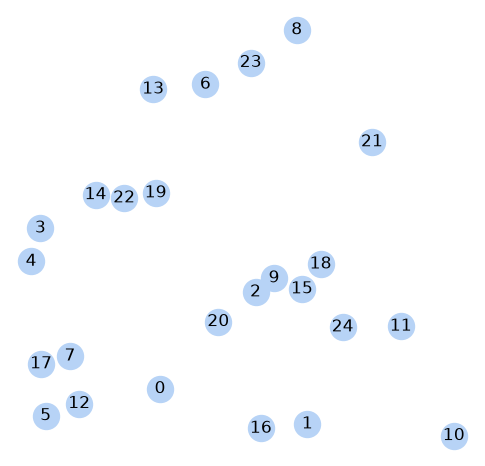

In [2]:
def build_random_nodes(num_nodes, seed):
    """Nodes at random positions in the unit square without edges."""
    rng = random.Random(seed)
    graph = nx.Graph()
    for node_id in range(num_nodes):
        graph.add_node(node_id, pos=(rng.random(), rng.random()))
    return graph

num_nodes = 25
G_nodes = build_random_nodes(num_nodes, seed=7)

print(G_nodes)
print("Connected:", nx.is_connected(G_nodes))
print("Number of connected components:", nx.number_connected_components(G_nodes))

pos_nodes = nx.get_node_attributes(G_nodes, "pos")
fig, axes = plt.subplots(figsize=(6, 6))
nx.draw(
    G_nodes,
    pos_nodes,
    with_labels=True,
    node_color=NODE_COLOR,
    node_size=350,
    ax=axes,
)
axes.set_aspect("equal")


# Exercise 2: Graph with x nodes at random position and all nodes are connected with edges


Graph with 25 nodes and 300 edges
Connected: True
Number of connected components: 1


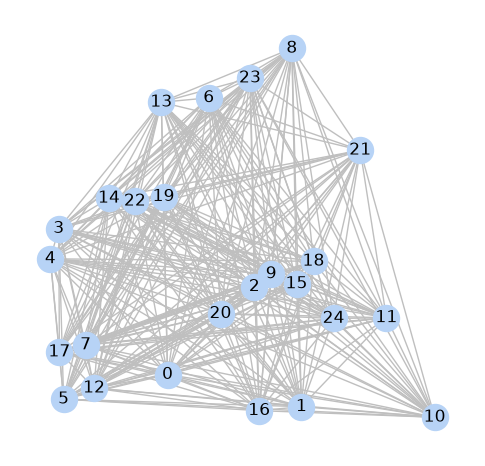

In [3]:
import math
import random

def build_roadmap_all(num_nodes, seed):
    """Nodes at random positions in the unit square, all nodes connected to each other."""
    rng = random.Random(seed)
    graph = nx.Graph()
    for node_id in range(num_nodes):
        graph.add_node(node_id, pos=(rng.random(), rng.random()))

    for node_a in graph.nodes:
        for node_b in graph.nodes:
            if node_a >= node_b:
                continue
            distance = math.dist(graph.nodes[node_a]["pos"], graph.nodes[node_b]["pos"])
            graph.add_edge(node_a, node_b, weight=distance)
    return graph

num_nodes = 25
G_all = build_roadmap_all(num_nodes, seed=7)

print(G_all)
print("Connected:", nx.is_connected(G_all))
print("Number of connected components:", nx.number_connected_components(G_all))

pos_all = nx.get_node_attributes(G_all, "pos")
fig, axes = plt.subplots(figsize=(6, 6))
nx.draw(
    G_all,
    pos_all,
    with_labels=True,
    node_color=NODE_COLOR,
    node_size=350,
    edge_color="0.75",
    ax=axes,
)
axes.set_aspect("equal")


# Exercise 3: Graph with x nodes at random position, nodes with given distance are connected



Graph with 25 nodes and 58 edges
Connected: True
Number of connected components: 1


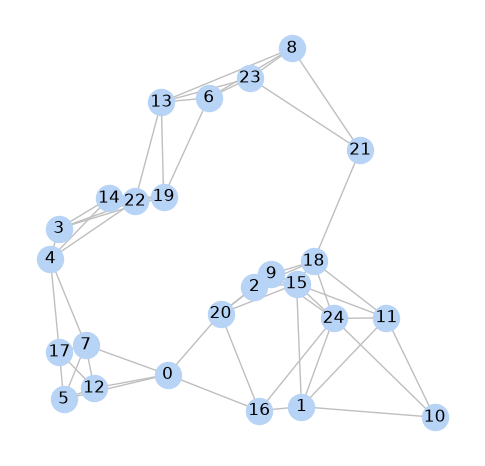

In [4]:
import math
import random

def build_roadmap_radius_knn(num_nodes, connection_radius, k_neighbors, seed):
    """Nodes at random positions in the unit square.
    Connects nodes within connection_radius, considering at most k_neighbors closest nodes.
    Set connection_radius=None to connect to k nearest neighbors without distance limit.
    """
    rng = random.Random(seed)
    graph = nx.Graph()
    for node_id in range(num_nodes):
        graph.add_node(node_id, pos=(rng.random(), rng.random()))

    for node_a in graph.nodes:
        candidates = []
        for node_b in graph.nodes:
            if node_a != node_b:
                distance = math.dist(graph.nodes[node_a]["pos"], graph.nodes[node_b]["pos"])
                if connection_radius is None or distance <= connection_radius:
                    candidates.append((distance, node_b))

        # Sort by distance and connect to the k closest neighbors
        candidates.sort(key=lambda item: item[0])
        for distance, node_b in candidates[:k_neighbors]:
            graph.add_edge(node_a, node_b, weight=distance)
    return graph

num_nodes = 25
G_knn = build_roadmap_radius_knn(num_nodes, connection_radius=0.35, k_neighbors=4, seed=7)

print(G_knn)
print("Connected:", nx.is_connected(G_knn))
print("Number of connected components:", nx.number_connected_components(G_knn))

pos_knn = nx.get_node_attributes(G_knn, "pos")
fig, axes = plt.subplots(figsize=(6, 6))
nx.draw(
    G_knn,
    pos_knn,
    with_labels=True,
    node_color=NODE_COLOR,
    node_size=350,
    edge_color="0.75",
    ax=axes,
)
axes.set_aspect("equal")
